PROJECT INFORMATION

Name: Chimamaka Victor Daniel 
Project Buddy: Umeizudike Franklyn Chukwuemeka 
Industry: Education and Education Technology (EdTech) 
Project Title: Challenges of Monitoring Academic Performance in Nigerian Primary Schools

In [196]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [197]:

df = pd.read_excel("school_results.xlsx")

print("Dataset dimensions:", df.shape)
print("\nColumns names:")
print(df.columns.tolist())

print("\nFirst five records:")
print(df.head())

Dataset dimensions: (74, 16)

Columns names:
['s/n', 'school', 'student ID', 'class', 'english', 'maths', 'basic science', 'social studies', 'yoruba', 'physical and health education', 'religious knowledge', 'cultural and creative arts', 'agriculture', 'home economics', 'civil', 'computer']

First five records:
   s/n                            school student ID      class  english  \
0    1  Selected primary school Oyapidan   PUPIL028  Primary 5     78.5   
1    2  Selected primary school Oyapidan   PUPIL029  Primary 5     75.0   
2    3  Selected primary school Oyapidan   PUPIL030  Primary 5     73.0   
3    4  Selected primary school Oyapidan   PUPIL031  Primary 5     74.0   
4    5  Selected primary school Oyapidan   PUPIL032  Primary 5     71.0   

   maths  basic science  social studies  yoruba  \
0   77.0           84.0            84.0    84.0   
1   76.5           86.5            79.5    86.0   
2   73.0           76.5            81.0    80.0   
3   66.0           84.0          

In [198]:
df.columns = df.columns.str.strip()


df = df.dropna(how="all")


df["student ID"] = df["student ID"].astype("string").str.strip()

df["school"] = df["school"].astype("string").str.strip()


In [199]:
#5Standardis class names
df["class"]= (
    df["class"]
        .astype("string")
        .str.strip()
        .str.upper()
        .replace({
          "P4":"PRIMARY 4",
          "PRI 4":"PRIMARY 4",
          "P5":"PRIMARY 5",
          "PRI 5":"PRIMARY 5",
          "P6":"PRIMARY 6",
          "PRI 6":"PRIMARY 6",
       })
)

In [200]:
#Replace these with the actual 12 subject column names
#Convert subject scores to numeric for col in subject_cols:

subject_cols = [
    "english","maths","basic science","social studies","civil",
    "computer","agriculture","physical and health education","religious knowledge",
    "yoruba","cultural and creative arts","home economics"]


df[subject_cols] = df[subject_cols].apply(
    pd.to_numeric,errors="coerce"
)

In [201]:
df[subject_cols].dtypes

english                          float64
maths                            float64
basic science                    float64
social studies                   float64
civil                            float64
computer                         float64
agriculture                      float64
physical and health education    float64
religious knowledge              float64
yoruba                           float64
cultural and creative arts       float64
home economics                   float64
dtype: object

In [202]:
#check if any subject has missing values
df[subject_cols].isnull().sum()

english                          0
maths                            0
basic science                    0
social studies                   0
civil                            0
computer                         0
agriculture                      0
physical and health education    0
religious knowledge              0
yoruba                           0
cultural and creative arts       0
home economics                   0
dtype: int64

In [203]:
#check duplicate student records
print("\nDuplicate student IDs:")

print(
    df[df.duplicated
        (subset=["student ID"],
         keep=False
        )]
)


Duplicate student IDs:
    s/n                            school student ID      class  english  \
0     1  Selected primary school Oyapidan   PUPIL028  PRIMARY 5     78.5   
51   52  Selected primary school Oyapidan   PUPIL028  PRIMARY 6     64.0   

    maths  basic science  social studies  yoruba  \
0    77.0           84.0            84.0    84.0   
51   40.0           52.0            51.0    50.0   

    physical and health education  religious knowledge  \
0                            86.0                 85.0   
51                           40.0                 53.0   

    cultural and creative arts  agriculture  home economics  civil  computer  
0                         85.0         82.5            89.5   89.5      84.0  
51                        30.0         50.0            30.0   58.0      65.0  


In [204]:
# Check scores outside 0-100

for col in subject_cols:
    invalid = df[
        ~df[col].between(0, 100) & df[col].notna()
    ]

    print(f"{col}: {len(invalid)} invalid scores")

english: 0 invalid scores
maths: 0 invalid scores
basic science: 0 invalid scores
social studies: 0 invalid scores
civil: 0 invalid scores
computer: 0 invalid scores
agriculture: 0 invalid scores
physical and health education: 0 invalid scores
religious knowledge: 0 invalid scores
yoruba: 0 invalid scores
cultural and creative arts: 0 invalid scores
home economics: 0 invalid scores


In [205]:
#calculate total and average

df["Total Score"] = df[subject_cols].sum(
    axis=1,min_count=1
)
df["Average Score"] = df[subject_cols].mean(
    axis=1
).round(2)

In [206]:
#PUPIL PERFORMANCE CATEGORISED
df["Missing Subject Count"] = df[subject_cols].isnull().sum(axis=1)

def classify(row):
    if row["Missing Subject Count"] > 0:
        return "Incomplete Record"
    elif row["Average Score"] < 50:
        return "Needs Support"
    elif row["Average Score"] < 70:
        return "Satisfactory"
    else:
        return "High Performance"

df["Performance Category"] = df.apply(
    classify,
    axis=1
)

*Performance analysis*

In [207]:
#combined
print("n\Average Score by class:")

print(
    df.groupby("class")["Average Score"]
      .mean().round(2)
)

print("\nAverage Score by subject:")
print(df[subject_cols].mean().round(2))


n\Average Score by class:
class
PRIMARY 4    55.12
PRIMARY 5    72.15
PRIMARY 6    55.67
Name: Average Score, dtype: float64

Average Score by subject:
english                          59.05
maths                            57.03
basic science                    61.42
social studies                   61.59
civil                            62.32
computer                         61.01
agriculture                      60.90
physical and health education    60.03
religious knowledge              65.19
yoruba                           63.71
cultural and creative arts       58.61
home economics                   59.36
dtype: float64


*STEP 5: Identify academic challenges*

In [208]:
#class performance
print("\nPupils needing academic support:")

print(
    df[df["Average Score"] < 50][
    ["student ID", "class", "Average Score"]
        ]
)

print("\nSubjects below the 50% threshold:")

print(
    df[subject_cols].mean()[
        df[subject_cols].mean()<50
    ]
     )


Pupils needing academic support:
   student ID      class  Average Score
25   PUPIL002  PRIMARY 6          42.92
30   PUPIL007  PRIMARY 6          41.17
31   PUPIL008  PRIMARY 6          48.17
34   PUPIL011  PRIMARY 6          45.50
47   PUPIL024  PRIMARY 6          46.67
49   PUPIL026  PRIMARY 6          45.00
51   PUPIL028  PRIMARY 6          48.58
57   PUPIL057  PRIMARY 4          49.54
65   PUPIL065  PRIMARY 4          49.50
67   PUPIL067  PRIMARY 4          48.38

Subjects below the 50% threshold:
Series([], dtype: float64)


*EXPORT RESULTS*

In [209]:
df[["student ID", "class", "Total Score","Average Score"]].head(50)

,student ID,class,Total Score,Average Score
0,PUPIL028,PRIMARY 5,1009.0,84.08
1,PUPIL029,PRIMARY 5,980.0,81.67
2,PUPIL030,PRIMARY 5,967.0,80.58
3,PUPIL031,PRIMARY 5,961.0,80.08
4,PUPIL032,PRIMARY 5,940.5,78.38
5,PUPIL033,PRIMARY 5,939.5,78.29
6,PUPIL034,PRIMARY 5,905.5,75.46
7,PUPIL035,PRIMARY 5,899.5,74.96
8,PUPIL036,PRIMARY 5,894.5,74.54
9,PUPIL037,PRIMARY 5,891.5,74.29


Visualization

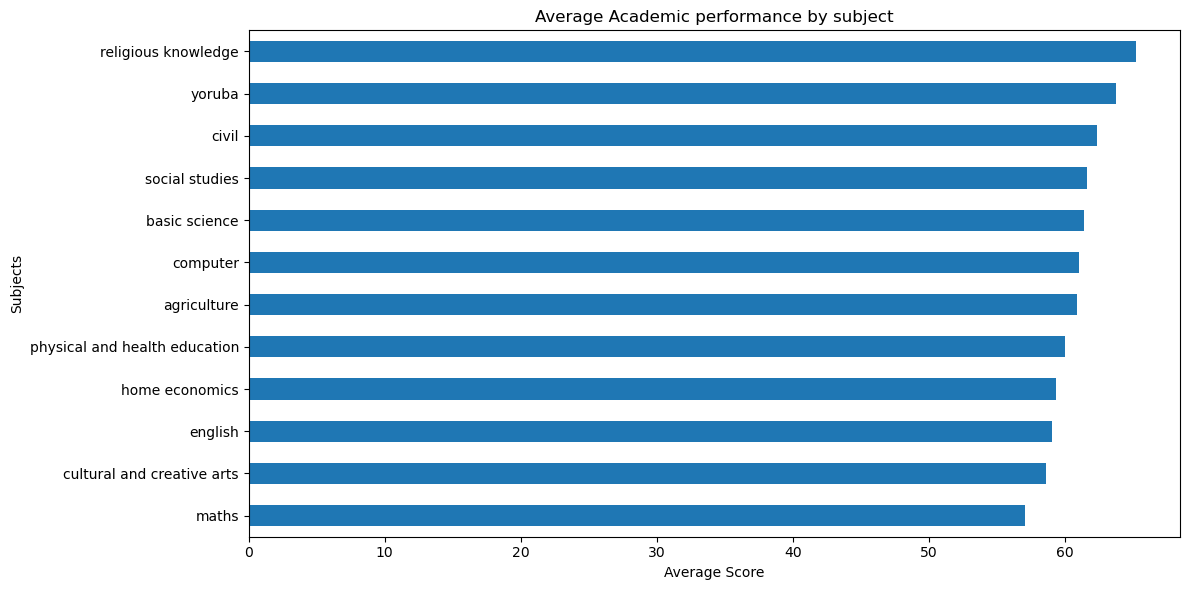

In [210]:
#Average performance by subject

plt.figure(figsize=(12,6))
subject_performance.sort_values().plot(
    kind="barh"
)
plt.title("Average Academic performance by subject")
plt.xlabel("Average Score")
plt.ylabel("Subjects")
plt.tight_layout()
plt.show()

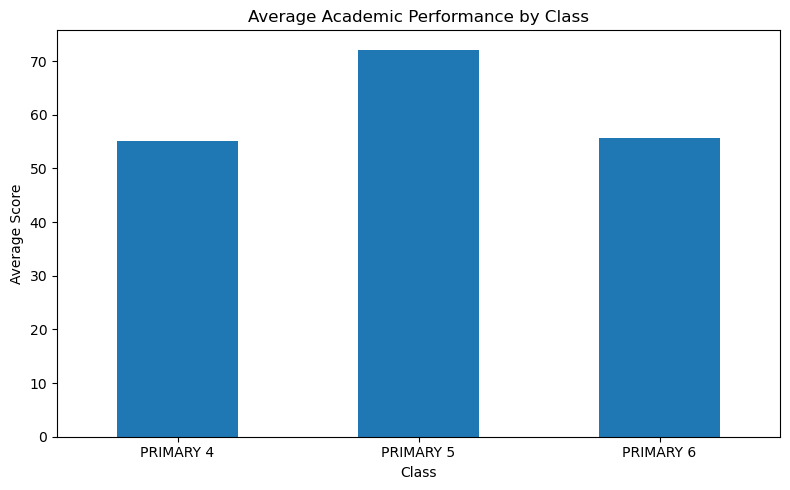

In [211]:

#compare academic performance across classes
plt.figure(figsize=(8, 5))

class_analysis["Average_performance"].plot(
    kind="bar"
)

plt.title("Average Academic Performance by Class")
plt.xlabel("Class")
plt.ylabel("Average Score")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

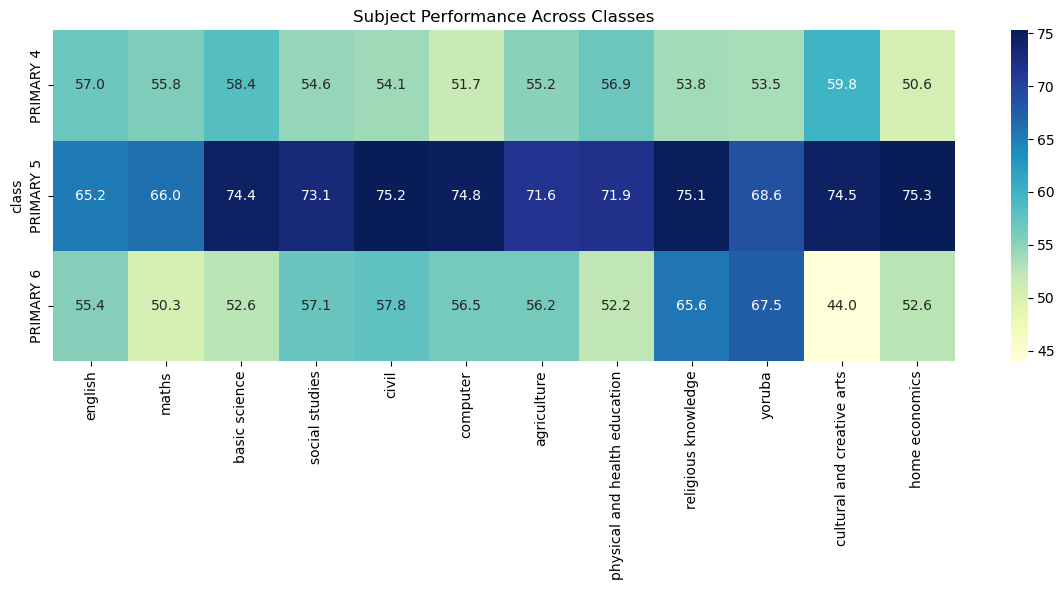

In [212]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.groupby("class")[subject_cols].mean(),
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Subject Performance Across Classes")
plt.tight_layout()
plt.show()
#done

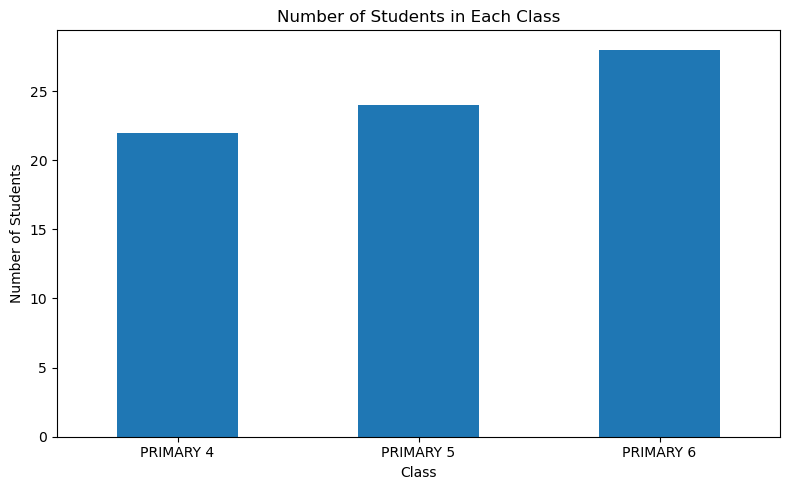

In [213]:
#Number of pupil in each class
plt.figure(figsize=(8, 5))

class_analysis["Number_of_Students"].plot(
    kind="bar"
)

plt.title("Number of Students in Each Class")
plt.xlabel("Class")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [214]:
print("Total students:", len(df))
print("Average class score:", df["Average Score"].mean())
print("Highest student average:", df["Average Score"].max())
print("Lowest student average:", df["Average Score"].min())
#done

Total students: 74
Average class score: 60.851216216216216
Highest student average: 84.08
Lowest student average: 41.17


In [215]:
#Class performance analysis
class_analysis = df.groupby("class").agg(
    Number_of_Students=("student ID", "count"),
    Average_performance=("Average Score", "mean"),
    Highest_Average=("Average Score", "max"),
    Lowest_Average=("Average Score", "min")
)
class_analysis.round(2)

,Number_of_Students,Average_performance,Highest_Average,Lowest_Average
class,,,,
PRIMARY 4,22,55.12,77.54,48.38
PRIMARY 5,24,72.15,84.08,51.38
PRIMARY 6,28,55.67,79.25,41.17


In [216]:
#How pupil performed in the 12 subject
#Average performance in each subject
subject_performance = df[subject_cols].mean().round(2)

print("Average performance by subject:")
print(subject_performance)

Average performance by subject:
english                          59.05
maths                            57.03
basic science                    61.42
social studies                   61.59
civil                            62.32
computer                         61.01
agriculture                      60.90
physical and health education    60.03
religious knowledge              65.19
yoruba                           63.71
cultural and creative arts       58.61
home economics                   59.36
dtype: float64


In [217]:
#17identify strongest and weakest subjects
strongest_subject = subject_performance.idxmax()
weakest_subject = subject_performance.idxmin()

highest_subject_score = subject_performance.max()
lowest_subject_score = subject_performance.min()

print("Strongest subject:", strongest_subject)
print("Average score:", highest_subject_score)

print("Weakest subject", weakest_subject)
print("Average score:", lowest_subject_score)

Strongest subject: religious knowledge
Average score: 65.19
Weakest subject maths
Average score: 57.03


In [226]:
#Arrange pupils from lowest to highest average
#10 pupils with lowest recorded  averages

ranked_students = df.sort_values(
    by="Average Score",
    ascending=True
)

ranked_students[
    ["student ID", "class", "Average Score"]
].head(10)


,student ID,class,Average Score
30,PUPIL007,PRIMARY 6,41.17
25,PUPIL002,PRIMARY 6,42.92
49,PUPIL026,PRIMARY 6,45.00
34,PUPIL011,PRIMARY 6,45.50
47,PUPIL024,PRIMARY 6,46.67
31,PUPIL008,PRIMARY 6,48.17
67,PUPIL067,PRIMARY 4,48.38
51,PUPIL028,PRIMARY 6,48.58
65,PUPIL065,PRIMARY 4,49.50
57,PUPIL057,PRIMARY 4,49.54


In [227]:
ranked_students = ranked_students.copy()

ranked_students["Weakest Subject"] = (
    ranked_students[subject_cols].idxmin(axis=1)
)

ranked_students["Lowest Subject Score"] = (
    ranked_students[subject_cols].min(axis=1)
)

ranked_students[
    [
        "student ID",
        "class",
        "Average Score",
        "Weakest Subject",
        "Lowest Subject Score"
    ]
].head(10)

,student ID,class,Average Score,Weakest Subject,Lowest Subject Score
30,PUPIL007,PRIMARY 6,41.17,computer,29.0
25,PUPIL002,PRIMARY 6,42.92,physical and health education,26.0
49,PUPIL026,PRIMARY 6,45.00,social studies,26.0
34,PUPIL011,PRIMARY 6,45.50,cultural and creative arts,30.0
47,PUPIL024,PRIMARY 6,46.67,basic science,20.0
31,PUPIL008,PRIMARY 6,48.17,computer,30.0
67,PUPIL067,PRIMARY 4,48.38,home economics,4.5
51,PUPIL028,PRIMARY 6,48.58,cultural and creative arts,30.0
65,PUPIL065,PRIMARY 4,49.50,maths,5.0
57,PUPIL057,PRIMARY 4,49.54,home economics,39.5


In [228]:
#19
df.to_excel("cleaned_school_results.xlsx",index=False)

df.groupby("class")[subject_cols].mean().to_excel(
    "class_subject_analysis.xlsx"
)

print("Analysis completed successfully.")

Analysis completed successfully.


In [229]:
class_analysis.round(2).to_excel(
    "class_performance_summary.xlsx"
)

ranked_students[
    [
        "student ID",
        "class",
        "Average Score",
        "Weakest Subject",
        "Lowest Subject Score"
    ]
].head(10).to_excel(
    "pupils_requiring_review.xlsx",
    index=False
)

Project Finding
- A total of 74 pupils were analysed.
- The overall mean student average was approximately 60.85.
- The highest individual average was approximately 84.08.
- The lowest individual average was approximately 41.17.
- Primary 5 recorded the highest class average of 72.15.
- Primary 4 recorded an average of 55.12.
- Primary 6 recorded an average of 55.67.

 Recommendations
1. Maintain organised digital academic records.
2. Provide additional support to pupils with low averages.
3. Give more attention to subjects with low averages.
4. Investigate the performance of Primary 4 and Primary 6.
5. Analyse results from successive assessment periods.
6. Combine data analysis with classroom observations and professional judgement.

Conclusion

This project demonstrated how Python can support the monitoring of academic 
performance by analysing 74 pupils' records across Primary 4, Primary 5 and
Primary 6 in a selected school in Ibadan, Oyo State.
The findings revealed differences in class and subject performance and 
identified pupils who may require additional academic support. This shows
that Python-based data analysis can help teachers and school administrators
make informed academic decisions.
The project recommends digital record-keeping and further analysis involving
more schools and multiple assessment periods for broader monitoring of pupils
' academic performance.